# Práctica 4 — Red neuronal densa con MNIST (dígitos escritos a mano)

**Objetivo de esta práctica:** entrenar una red neuronal densa que reciba una imagen de 28 × 28 píxeles de un dígito escrito a mano y prediga qué número es (del 0 al 9).

Es el primer ejercicio del curso en el que la red trabaja con **imágenes** en lugar de una tabla de datos. Como las capas `Dense` solo aceptan vectores, la imagen se "aplana" con `Flatten` antes de entrar a la red.

## 1. Importar librerías

In [1]:
import tensorflow as tf                          # TensorFlow: para construir y entrenar la red neuronal
import matplotlib.pyplot as plt                  # Para mostrar las imágenes de los dígitos
from tensorflow.keras.datasets import mnist      # Dataset MNIST: dígitos manuscritos (70 000 imágenes)

## 2. Cargar el dataset

`mnist.load_data()` ya viene separado en entrenamiento (60 000 imágenes) y prueba (10 000 imágenes). Cada imagen es una matriz de 28 × 28 y su etiqueta es el dígito que representa.

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 7s 1us/step


## 3. Explorar la forma de los datos

In [3]:
print("Forma de la imagen:", x_test[0].shape)                   # (28, 28): una imagen
print("Forma de x_train:", x_train.shape)                       # (60000, 28, 28)
print("Forma de x_test:", x_test.shape)                         # (10000, 28, 28)
print("Total de muestras:", (len(y_train) + len(y_test)))       # 70000

Forma de la imagen: (28, 28)
Forma de x_train: (60000, 28, 28)
Forma de x_test: (10000, 28, 28)
Total de muestras: 70000


## 4. Visualizar las primeras 10 imágenes de prueba con su etiqueta

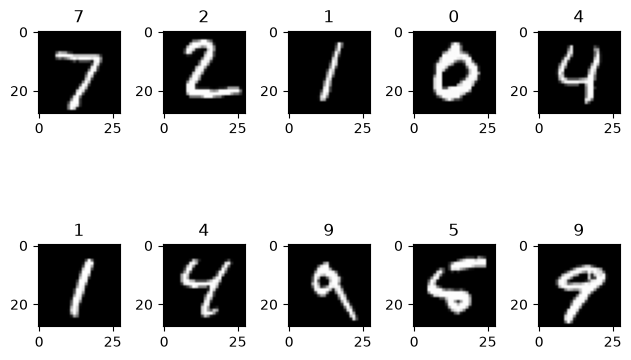

In [4]:
for s in range(10):
    plt.subplot(2, 5, s + 1)                  # Cuadrícula de 2 filas x 5 columnas
    plt.imshow(x_test[s], cmap="gray")        # Muestra la imagen en escala de grises
    plt.title(y_test[s])                      # Título: el dígito real
plt.tight_layout()

## 5. Normalizar los píxeles

Cada píxel va de 0 (negro) a 255 (blanco). Al dividir entre 255.0 todos quedan entre 0 y 1, lo que ayuda a que la red aprenda más rápido y de forma estable.

In [5]:
x_train = x_train / 255.0
x_test = x_test / 255.0

## 6. Construir el modelo

Arquitectura: `Flatten` convierte la imagen de 28 × 28 en un vector de 784 valores → una capa oculta de 128 neuronas con `relu` → una capa de salida de 10 neuronas con `softmax` (una probabilidad por cada dígito).

In [6]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),        # Convierte la imagen 2D en un vector plano (las capas densas solo admiten vectores)
    tf.keras.layers.Dense(128, activation="relu"),        # Capa oculta: 128 neuronas
    tf.keras.layers.Dense(10, activation="softmax")       # Capa de salida: 10 probabilidades (dígitos 0 al 9)
])

c:\Users\ANT DOR\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 7. Compilar y entrenar

`sparse_categorical_crossentropy` porque las etiquetas son números enteros (0 al 9). Se entrena durante 15 épocas.

In [7]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=15)

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9269 - loss: 0.2593
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9669 - loss: 0.1118
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9772 - loss: 0.0763
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9829 - loss: 0.0570
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9867 - loss: 0.0440
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9892 - loss: 0.0338
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.9914 - loss: 0.0269
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9930 - loss: 0.0225
Epoch 9/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9943 - loss: 0.0190
Epoch 10/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9956 - loss: 0.0149
Epoch 11/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9956 - loss: 0.0136
Epoch 12/15
1875/1875 ━━━━

## 8. Predecir una imagen de prueba

`predict` devuelve 10 probabilidades; `argmax(1)` se queda con la posición de la más alta, que es el dígito predicho.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
Salida de probabilidades de nuestro softmax: [[1.0000000e+00 6.0502915e-22 9.2825014e-10 3.5764552e-15 6.1152532e-25
  1.8257552e-15 4.2071134e-12 1.0613248e-13 1.5863433e-19 1.1274947e-13]]
Afinando la salida: [0]
Etiqueta real: 0


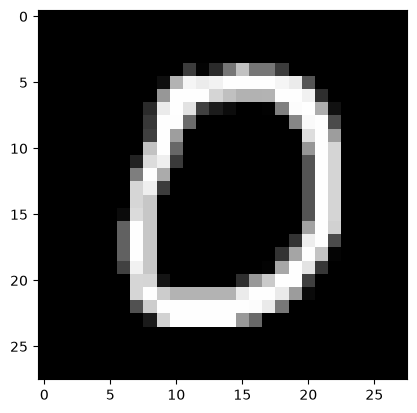

In [8]:
muestra = x_test[10].reshape(1, 28, 28)         # Una sola imagen, con la forma que espera el modelo
predict = model.predict(muestra)

print("Salida de probabilidades de nuestro softmax:", predict)
print("Afinando la salida:", predict.argmax(1))   # Dígito con mayor probabilidad
print("Etiqueta real:", y_test[10])
plt.imshow(muestra.reshape(28, 28), cmap="gray")

## 🗒️ Conclusión

Con solo una capa oculta de 128 neuronas, la red aprende a reconocer dígitos escritos a mano. La clave fue preparar la imagen: normalizar los píxeles entre 0 y 1 y aplanarla con `Flatten` para que las capas densas puedan procesarla.